<a href="https://colab.research.google.com/github/pablo2fp/Analise-multivariada-em-sistemas-de-bioflocos/blob/main/dados_mestrado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bibliotecas

In [ ]:
# ==========================================================
# PCA + CLUSTERING + HEATMAP + NETWORK ANALYSIS
# Artigo Biofloc HBFT x QBFT x CSW
# ==========================================================
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx


#Dados

In [ ]:
df = pd.read_excel('/content/Dados mestrado.xlsx', sheet_name='Planilha3')
display(df)

,Tanques,o2m_mean,tempt_mean,amo_mean,nit_mean,nitra_mean,nitra_min,ph_mean,alc_mean,turb_mean,...,hepat2_mean,vibri1_mean,vibri2_mean,filament1_mean,filament2_mean,coc1_mean,coc2_mean,coc2_std,bacil1_mean,bacil2_mean
0,HBFT1,5.887556,28.323333,1.302609,3.979130,5.083846,0.0,7.803400,188.292683,210.033333,...,55.861470,17311.111111,8.200000e+05,13032.142857,1.435000e+06,491863.333333,4.072667e+06,2.574972e+06,28290.000000,3.403000e+06
1,HBFT2,5.963667,28.227778,1.233111,3.700109,4.290000,0.0,7.853380,193.170732,232.593333,...,56.888183,17311.111111,8.200000e+05,13032.142857,6.560000e+05,491863.333333,5.384667e+06,2.817478e+06,28290.000000,1.694667e+06
2,HBFT3,5.998778,27.896667,0.798696,2.190870,8.000000,1.0,7.879400,194.390244,261.486667,...,57.645643,17311.111111,8.200000e+05,13032.142857,1.045500e+06,491863.333333,4.728667e+06,2.696225e+06,28290.000000,2.548833e+06
3,QBFT1,6.306333,27.840111,0.282174,0.479130,43.923077,2.0,7.727600,139.268293,163.186667,...,50.956244,19608.695652,1.047778e+06,21320.000000,3.562759e+06,369410.000000,6.491667e+06,2.974307e+06,32936.666667,3.703667e+06
4,QBFT2,6.121556,27.901111,0.660652,1.697609,38.946154,1.1,7.766735,136.829268,190.846667,...,58.330559,19608.695652,1.066000e+06,21320.000000,1.066000e+06,369410.000000,7.011000e+06,5.012615e+06,32936.666667,1.108519e+06
5,QBFT3,6.093556,27.382222,1.025652,2.098696,48.442308,0.7,7.780000,139.024390,223.366667,...,68.840361,19608.695652,3.499643e+06,21320.000000,3.499643e+06,369410.000000,5.658000e+06,3.949349e+06,32936.666667,1.522857e+06
6,CSW1,6.467489,27.440889,1.913111,0.839130,4.800769,0.0,7.968200,169.268293,0.780000,...,71.824488,30476.666667,2.542000e+04,4783.333333,9.111111e+04,241900.000000,9.868276e+04,4.488559e+04,22140.000000,2.665000e+04
7,CSW2,6.423111,26.922222,1.877174,0.870000,3.157692,0.0,8.004898,166.341463,1.533333,...,67.710183,30476.666667,2.225714e+04,4783.333333,7.323448e+04,241900.000000,1.355733e+05,8.173756e+04,22140.000000,3.088667e+04
8,CSW3,6.340778,27.653333,1.549565,0.738913,3.693077,0.0,8.018000,170.000000,2.353333,...,66.674249,30476.666667,2.383857e+04,4783.333333,8.217280e+04,241900.000000,1.171280e+05,6.331157e+04,22140.000000,2.876833e+04


In [ ]:
df.set_index("Tanques", inplace=True)
display(df)

,o2m_mean,tempt_mean,amo_mean,nit_mean,nitra_mean,nitra_min,ph_mean,alc_mean,turb_mean,sst_mean,...,hepat2_mean,vibri1_mean,vibri2_mean,filament1_mean,filament2_mean,coc1_mean,coc2_mean,coc2_std,bacil1_mean,bacil2_mean
Tanques,,,,,,,,,,,,,,,,,,,,,
HBFT1,5.887556,28.323333,1.302609,3.979130,5.083846,0.0,7.803400,188.292683,210.033333,363.461538,...,55.861470,17311.111111,8.200000e+05,13032.142857,1.435000e+06,491863.333333,4.072667e+06,2.574972e+06,28290.000000,3.403000e+06
HBFT2,5.963667,28.227778,1.233111,3.700109,4.290000,0.0,7.853380,193.170732,232.593333,392.307692,...,56.888183,17311.111111,8.200000e+05,13032.142857,6.560000e+05,491863.333333,5.384667e+06,2.817478e+06,28290.000000,1.694667e+06
HBFT3,5.998778,27.896667,0.798696,2.190870,8.000000,1.0,7.879400,194.390244,261.486667,421.538462,...,57.645643,17311.111111,8.200000e+05,13032.142857,1.045500e+06,491863.333333,4.728667e+06,2.696225e+06,28290.000000,2.548833e+06
QBFT1,6.306333,27.840111,0.282174,0.479130,43.923077,2.0,7.727600,139.268293,163.186667,355.384615,...,50.956244,19608.695652,1.047778e+06,21320.000000,3.562759e+06,369410.000000,6.491667e+06,2.974307e+06,32936.666667,3.703667e+06
QBFT2,6.121556,27.901111,0.660652,1.697609,38.946154,1.1,7.766735,136.829268,190.846667,337.692308,...,58.330559,19608.695652,1.066000e+06,21320.000000,1.066000e+06,369410.000000,7.011000e+06,5.012615e+06,32936.666667,1.108519e+06
QBFT3,6.093556,27.382222,1.025652,2.098696,48.442308,0.7,7.780000,139.024390,223.366667,334.615385,...,68.840361,19608.695652,3.499643e+06,21320.000000,3.499643e+06,369410.000000,5.658000e+06,3.949349e+06,32936.666667,1.522857e+06
CSW1,6.467489,27.440889,1.913111,0.839130,4.800769,0.0,7.968200,169.268293,0.780000,80.769231,...,71.824488,30476.666667,2.542000e+04,4783.333333,9.111111e+04,241900.000000,9.868276e+04,4.488559e+04,22140.000000,2.665000e+04
CSW2,6.423111,26.922222,1.877174,0.870000,3.157692,0.0,8.004898,166.341463,1.533333,89.615385,...,67.710183,30476.666667,2.225714e+04,4783.333333,7.323448e+04,241900.000000,1.355733e+05,8.173756e+04,22140.000000,3.088667e+04
CSW3,6.340778,27.653333,1.549565,0.738913,3.693077,0.0,8.018000,170.000000,2.353333,107.307692,...,66.674249,30476.666667,2.383857e+04,4783.333333,8.217280e+04,241900.000000,1.171280e+05,6.331157e+04,22140.000000,2.876833e+04


##Identificação

In [ ]:
X = df.reset_index(drop=True)
display(X)

,o2m_mean,tempt_mean,amo_mean,nit_mean,nitra_mean,nitra_min,ph_mean,alc_mean,turb_mean,sst_mean,...,hepat2_mean,vibri1_mean,vibri2_mean,filament1_mean,filament2_mean,coc1_mean,coc2_mean,coc2_std,bacil1_mean,bacil2_mean
0,5.887556,28.323333,1.302609,3.979130,5.083846,0.0,7.803400,188.292683,210.033333,363.461538,...,55.861470,17311.111111,8.200000e+05,13032.142857,1.435000e+06,491863.333333,4.072667e+06,2.574972e+06,28290.000000,3.403000e+06
1,5.963667,28.227778,1.233111,3.700109,4.290000,0.0,7.853380,193.170732,232.593333,392.307692,...,56.888183,17311.111111,8.200000e+05,13032.142857,6.560000e+05,491863.333333,5.384667e+06,2.817478e+06,28290.000000,1.694667e+06
2,5.998778,27.896667,0.798696,2.190870,8.000000,1.0,7.879400,194.390244,261.486667,421.538462,...,57.645643,17311.111111,8.200000e+05,13032.142857,1.045500e+06,491863.333333,4.728667e+06,2.696225e+06,28290.000000,2.548833e+06
3,6.306333,27.840111,0.282174,0.479130,43.923077,2.0,7.727600,139.268293,163.186667,355.384615,...,50.956244,19608.695652,1.047778e+06,21320.000000,3.562759e+06,369410.000000,6.491667e+06,2.974307e+06,32936.666667,3.703667e+06
4,6.121556,27.901111,0.660652,1.697609,38.946154,1.1,7.766735,136.829268,190.846667,337.692308,...,58.330559,19608.695652,1.066000e+06,21320.000000,1.066000e+06,369410.000000,7.011000e+06,5.012615e+06,32936.666667,1.108519e+06
5,6.093556,27.382222,1.025652,2.098696,48.442308,0.7,7.780000,139.024390,223.366667,334.615385,...,68.840361,19608.695652,3.499643e+06,21320.000000,3.499643e+06,369410.000000,5.658000e+06,3.949349e+06,32936.666667,1.522857e+06
6,6.467489,27.440889,1.913111,0.839130,4.800769,0.0,7.968200,169.268293,0.780000,80.769231,...,71.824488,30476.666667,2.542000e+04,4783.333333,9.111111e+04,241900.000000,9.868276e+04,4.488559e+04,22140.000000,2.665000e+04
7,6.423111,26.922222,1.877174,0.870000,3.157692,0.0,8.004898,166.341463,1.533333,89.615385,...,67.710183,30476.666667,2.225714e+04,4783.333333,7.323448e+04,241900.000000,1.355733e+05,8.173756e+04,22140.000000,3.088667e+04
8,6.340778,27.653333,1.549565,0.738913,3.693077,0.0,8.018000,170.000000,2.353333,107.307692,...,66.674249,30476.666667,2.383857e+04,4783.333333,8.217280e+04,241900.000000,1.171280e+05,6.331157e+04,22140.000000,2.876833e+04


In [ ]:
y = df.index
display(y)

Index(['HBFT1', 'HBFT2', 'HBFT3', 'QBFT1', 'QBFT2', 'QBFT3', 'CSW1', 'CSW2',
       'CSW3'],
      dtype='object', name='Tanques')

##Correlação

In [ ]:
corr_matrix = X.corr().abs()
display(corr_matrix)
#

,o2m_mean,tempt_mean,amo_mean,nit_mean,nitra_mean,nitra_min,ph_mean,alc_mean,turb_mean,sst_mean,...,hepat2_mean,vibri1_mean,vibri2_mean,filament1_mean,filament2_mean,coc1_mean,coc2_mean,coc2_std,bacil1_mean,bacil2_mean
o2m_mean,1.000000,0.766951,0.419689,0.906108,0.051943,0.036221,0.556082,0.384165,0.892232,0.859345,...,0.563025,0.885653,0.422860,0.482228,0.252942,0.940565,0.650368,0.663122,0.546432,0.623287
tempt_mean,0.766951,1.000000,0.468142,0.698365,0.049379,0.127959,0.520332,0.384166,0.660005,0.719095,...,0.751382,0.736135,0.018427,0.364163,0.124396,0.801426,0.562538,0.485954,0.421276,0.660456
amo_mean,0.419689,0.468142,1.000000,0.058922,0.724008,0.905676,0.847864,0.396654,0.711027,0.788037,...,0.767180,0.744718,0.463667,0.884092,0.724484,0.534316,0.894485,0.804055,0.889141,0.731144
nit_mean,0.906108,0.698365,0.058922,1.000000,0.215698,0.319190,0.338555,0.556276,0.685861,0.633752,...,0.368921,0.693301,0.253741,0.203777,0.018904,0.829416,0.392591,0.413919,0.271800,0.435131
nitra_mean,0.051943,0.049379,0.724008,0.215698,1.000000,0.769794,0.765935,0.864661,0.388426,0.395167,...,0.215403,0.387734,0.752972,0.879267,0.845982,0.053581,0.701878,0.721122,0.839055,0.331707
nitra_min,0.036221,0.127959,0.905676,0.319190,0.769794,1.000000,0.702159,0.576238,0.425988,0.513036,...,0.577879,0.456794,0.356863,0.762727,0.718516,0.209558,0.695061,0.591812,0.743283,0.578147
ph_mean,0.556082,0.520332,0.847864,0.338555,0.765935,0.702159,1.000000,0.423176,0.779582,0.813479,...,0.675291,0.833939,0.649499,0.956774,0.813283,0.616147,0.941168,0.898301,0.965826,0.774811
alc_mean,0.384165,0.384166,0.396654,0.556276,0.864661,0.576238,0.423176,1.000000,0.103456,0.090243,...,0.095123,0.091042,0.460219,0.560556,0.563476,0.423774,0.315605,0.377485,0.491569,0.067741
turb_mean,0.892232,0.660005,0.711027,0.685861,0.388426,0.425988,0.779582,0.103456,1.000000,0.983446,...,0.650147,0.983408,0.609300,0.754824,0.542530,0.926777,0.877233,0.847020,0.803683,0.739101
sst_mean,0.859345,0.719095,0.788037,0.633752,0.395167,0.513036,0.813479,0.090243,0.983446,1.000000,...,0.772562,0.992615,0.524659,0.771369,0.563490,0.930373,0.903480,0.835842,0.819717,0.816159


##Filtro para correlação

In [ ]:
# 1. Filtrar mantendo o formato de matriz (mostrando apenas |r| >= 0.8)
corr_filtrada_matriz = corr_matrix[corr_matrix.abs() >= 0.8]
display("Matriz de correlação filtrada:")
display(corr_filtrada_matriz.dropna(how='all', axis=0).dropna(how='all', axis=1))

# 2. Filtrar e mostrar como uma lista de pares de variáveis ordenados
# Criamos uma máscara para ignorar a diagonal principal e a parte inferior (evitar duplicados)
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
corr_triangulo = corr_matrix.where(mask)

# Transformamos a matriz em uma lista empilhada (stack) e filtramos
lista_correlacoes = corr_triangulo.stack().reset_index()
lista_correlacoes.columns = ['Variavel_1', 'Variavel_2', 'r']

# Filtramos apenas onde o valor absoluto de r é >= 0.8
lista_fortes = lista_correlacoes[lista_correlacoes['r'].abs() >= 0.8].sort_values(by='r', ascending=False)

display("Lista de pares com correlação forte (|r| >= 0.8):")
display(lista_fortes.reset_index(drop=True))

'Matriz de correlação filtrada:'

,o2m_mean,tempt_mean,amo_mean,nit_mean,nitra_mean,nitra_min,ph_mean,alc_mean,turb_mean,sst_mean,...,hepat2_mean,vibri1_mean,vibri2_mean,filament1_mean,filament2_mean,coc1_mean,coc2_mean,coc2_std,bacil1_mean,bacil2_mean
o2m_mean,1.000000,NaN,NaN,0.906108,NaN,NaN,NaN,NaN,0.892232,0.859345,...,NaN,0.885653,NaN,NaN,NaN,0.940565,NaN,NaN,NaN,NaN
tempt_mean,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.801426,NaN,NaN,NaN,NaN
amo_mean,NaN,NaN,1.000000,NaN,NaN,0.905676,0.847864,NaN,NaN,NaN,...,NaN,NaN,NaN,0.884092,NaN,NaN,0.894485,0.804055,0.889141,NaN
nit_mean,0.906108,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.829416,NaN,NaN,NaN,NaN
nitra_mean,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,0.864661,NaN,NaN,...,NaN,NaN,NaN,0.879267,0.845982,NaN,NaN,NaN,0.839055,NaN
nitra_min,NaN,NaN,0.905676,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ph_mean,NaN,NaN,0.847864,NaN,NaN,NaN,1.000000,NaN,NaN,0.813479,...,NaN,0.833939,NaN,0.956774,0.813283,NaN,0.941168,0.898301,0.965826,NaN
alc_mean,NaN,NaN,NaN,NaN,0.864661,NaN,NaN,1.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
turb_mean,0.892232,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.983446,...,NaN,0.983408,NaN,NaN,NaN,0.926777,0.877233,0.847020,0.803683,NaN
sst_mean,0.859345,NaN,NaN,NaN,NaN,NaN,0.813479,NaN,0.983446,1.000000,...,NaN,0.992615,NaN,NaN,NaN,0.930373,0.903480,0.835842,0.819717,0.816159


'Lista de pares com correlação forte (|r| >= 0.8):'

,Variavel_1,Variavel_2,r
0,filament1_mean,bacil1_mean,0.996674
1,sst_mean,vibri1_mean,0.992615
2,turb_mean,sst_mean,0.983446
3,turb_mean,vibri1_mean,0.983408
4,coc2_mean,bacil1_mean,0.969251
...,...,...,...
82,turb_mean,bacil1_mean,0.803683
83,gran2_mean,coc1_mean,0.802877
84,prot_mean,hepat1_mean,0.802461
85,turb_mean,prot_mean,0.802148


##Variáveis com fortes correlações

In [ ]:
# 1. Obter os nomes únicos de todas as variáveis que possuem correlação forte
variaveis_fortes = pd.concat([lista_fortes['Variavel_1'], lista_fortes['Variavel_2']]).unique()

# 2. Filtrar o DataFrame original (com os Tanques como índice) mantendo apenas essas colunas
df_correlacionado = df[variaveis_fortes]

# Exibir informações sobre o novo DataFrame
print(f"Número de colunas originais: {df.shape[1]}")
print(f"Número de colunas com correlação forte (r >= 0.8): {df_correlacionado.shape[1]}\n")

display(df_correlacionado)

Número de colunas originais: 33
Número de colunas com correlação forte (r >= 0.8): 26



,filament1_mean,sst_mean,turb_mean,coc2_mean,ph_mean,fag2_mean,coc2_std,o2m_mean,vibri1_mean,nitra_mean,...,nit_mean,linf1_mean,filament2_mean,fos_mean,tempt_mean,bacil1_mean,coc1_mean,nitra_min,bacil2_mean,linf2_mean
Tanques,,,,,,,,,,,,,,,,,,,,,
HBFT1,13032.142857,363.461538,210.033333,4.072667e+06,7.803400,44.083333,2.574972e+06,5.887556,17311.111111,5.083846,...,3.979130,441305.846167,1.435000e+06,0.26000,28.323333,28290.000000,491863.333333,0.0,3.403000e+06,748745.124722
HBFT2,13032.142857,392.307692,232.593333,5.384667e+06,7.853380,41.833333,2.817478e+06,5.963667,17311.111111,4.290000,...,3.700109,888282.501944,6.560000e+05,0.21750,28.227778,28290.000000,491863.333333,0.0,1.694667e+06,888282.501944
HBFT3,13032.142857,421.538462,261.486667,4.728667e+06,7.879400,42.146667,2.696225e+06,5.998778,17311.111111,8.000000,...,2.190870,620566.102722,1.045500e+06,0.30750,27.896667,28290.000000,491863.333333,1.0,2.548833e+06,585058.597306
QBFT1,21320.000000,355.384615,163.186667,6.491667e+06,7.727600,43.126667,2.974307e+06,6.306333,19608.695652,43.923077,...,0.479130,367508.396778,3.562759e+06,1.79875,27.840111,32936.666667,369410.000000,2.0,3.703667e+06,654964.478667
QBFT2,21320.000000,337.692308,190.846667,7.011000e+06,7.766735,43.750000,5.012615e+06,6.121556,19608.695652,38.946154,...,1.697609,961278.823778,1.066000e+06,3.18750,27.901111,32936.666667,369410.000000,1.1,1.108519e+06,896747.175111
QBFT3,21320.000000,334.615385,223.366667,5.658000e+06,7.780000,42.500000,3.949349e+06,6.093556,19608.695652,48.442308,...,2.098696,338045.787333,3.499643e+06,2.88750,27.382222,32936.666667,369410.000000,0.7,1.522857e+06,354701.660111
CSW1,4783.333333,80.769231,0.780000,9.868276e+04,7.968200,30.583333,4.488559e+04,6.467489,30476.666667,4.800769,...,0.839130,441066.681778,9.111111e+04,0.18750,27.440889,22140.000000,241900.000000,0.0,2.665000e+04,524025.903500
CSW2,4783.333333,89.615385,1.533333,1.355733e+05,8.004898,33.583333,8.173756e+04,6.423111,30476.666667,3.157692,...,0.870000,652033.717778,7.323448e+04,0.41500,26.922222,22140.000000,241900.000000,0.0,3.088667e+04,731638.257278
CSW3,4783.333333,107.307692,2.353333,1.171280e+05,8.018000,32.583333,6.331157e+04,6.340778,30476.666667,3.693077,...,0.738913,849211.509444,8.217280e+04,0.32625,27.653333,22140.000000,241900.000000,0.0,2.876833e+04,849211.509444


In [ ]:
X_corr = df_correlacionado.reset_index(drop=True)
display(X_corr)

,filament1_mean,sst_mean,turb_mean,coc2_mean,ph_mean,fag2_mean,coc2_std,o2m_mean,vibri1_mean,nitra_mean,...,nit_mean,linf1_mean,filament2_mean,fos_mean,tempt_mean,bacil1_mean,coc1_mean,nitra_min,bacil2_mean,linf2_mean
0,13032.142857,363.461538,210.033333,4.072667e+06,7.803400,44.083333,2.574972e+06,5.887556,17311.111111,5.083846,...,3.979130,441305.846167,1.435000e+06,0.26000,28.323333,28290.000000,491863.333333,0.0,3.403000e+06,748745.124722
1,13032.142857,392.307692,232.593333,5.384667e+06,7.853380,41.833333,2.817478e+06,5.963667,17311.111111,4.290000,...,3.700109,888282.501944,6.560000e+05,0.21750,28.227778,28290.000000,491863.333333,0.0,1.694667e+06,888282.501944
2,13032.142857,421.538462,261.486667,4.728667e+06,7.879400,42.146667,2.696225e+06,5.998778,17311.111111,8.000000,...,2.190870,620566.102722,1.045500e+06,0.30750,27.896667,28290.000000,491863.333333,1.0,2.548833e+06,585058.597306
3,21320.000000,355.384615,163.186667,6.491667e+06,7.727600,43.126667,2.974307e+06,6.306333,19608.695652,43.923077,...,0.479130,367508.396778,3.562759e+06,1.79875,27.840111,32936.666667,369410.000000,2.0,3.703667e+06,654964.478667
4,21320.000000,337.692308,190.846667,7.011000e+06,7.766735,43.750000,5.012615e+06,6.121556,19608.695652,38.946154,...,1.697609,961278.823778,1.066000e+06,3.18750,27.901111,32936.666667,369410.000000,1.1,1.108519e+06,896747.175111
5,21320.000000,334.615385,223.366667,5.658000e+06,7.780000,42.500000,3.949349e+06,6.093556,19608.695652,48.442308,...,2.098696,338045.787333,3.499643e+06,2.88750,27.382222,32936.666667,369410.000000,0.7,1.522857e+06,354701.660111
6,4783.333333,80.769231,0.780000,9.868276e+04,7.968200,30.583333,4.488559e+04,6.467489,30476.666667,4.800769,...,0.839130,441066.681778,9.111111e+04,0.18750,27.440889,22140.000000,241900.000000,0.0,2.665000e+04,524025.903500
7,4783.333333,89.615385,1.533333,1.355733e+05,8.004898,33.583333,8.173756e+04,6.423111,30476.666667,3.157692,...,0.870000,652033.717778,7.323448e+04,0.41500,26.922222,22140.000000,241900.000000,0.0,3.088667e+04,731638.257278
8,4783.333333,107.307692,2.353333,1.171280e+05,8.018000,32.583333,6.331157e+04,6.340778,30476.666667,3.693077,...,0.738913,849211.509444,8.217280e+04,0.32625,27.653333,22140.000000,241900.000000,0.0,2.876833e+04,849211.509444


In [ ]:
y_corr = df_correlacionado.index
display(y_corr)

Index(['HBFT1', 'HBFT2', 'HBFT3', 'QBFT1', 'QBFT2', 'QBFT3', 'CSW1', 'CSW2',
       'CSW3'],
      dtype='object', name='Tanques')

#PCA

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_corr)
display(X_scaled)

array([[-1.92797124e-03,  6.62849127e-01,  6.50825528e-01,
         1.22101725e-01, -6.22481041e-01,  9.23796466e-01,
         1.93430980e-01, -1.45352019e+00, -8.97680288e-01,
        -6.86965732e-01,  2.31435090e-01,  2.03365355e-01,
        -4.44572899e-01,  9.99733175e-01,  1.05593934e+00,
        -8.50727046e-01,  1.75971381e+00, -7.89593479e-01,
         1.20976446e-01, -6.96137753e-01,  1.43339827e+00,
         1.13323802e-01,  1.21640319e+00, -7.86357099e-01,
         1.37024213e+00,  3.27371250e-01],
       [-1.92797124e-03,  8.81104327e-01,  8.69562890e-01,
         6.09856106e-01, -1.32116387e-01,  4.84255149e-01,
         3.36063602e-01, -1.07274427e+00, -8.97680288e-01,
        -7.29800495e-01,  9.74913282e-02,  6.79059274e-01,
         2.08739827e-02,  1.22134890e+00,  1.13689159e+00,
        -6.99488988e-01,  1.52978090e+00,  1.21120975e+00,
        -4.83311006e-01, -7.32877690e-01,  1.20178509e+00,
         1.13323802e-01,  1.21640319e+00, -7.86357099e-01,
         9.79

In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [ ]:
autovalores = pca.explained_variance_
variancia_explicada = pca.explained_variance_ratio_
variancia_acumulada = np.cumsum(variancia_explicada)

tabela_pca = pd.DataFrame({
    "Autovalor": autovalores,
    "Variância Explicada (%)": variancia_explicada * 100,
    "Variância Acumulada (%)": variancia_acumulada * 100
})

tabela_pca

,Autovalor,Variância Explicada (%),Variância Acumulada (%)
0,1.788405e+01,6.114204e+01,61.142037
1,5.996511e+00,2.050089e+01,81.642929
2,2.392867e+00,8.180743e+00,89.823672
3,1.586819e+00,5.425021e+00,95.248693
4,7.268166e-01,2.484843e+00,97.733536
5,3.839912e-01,1.312790e+00,99.046326
6,1.746886e-01,5.972261e-01,99.643552
7,1.042610e-01,3.564478e-01,100.000000
8,5.279790e-32,1.805056e-31,100.000000


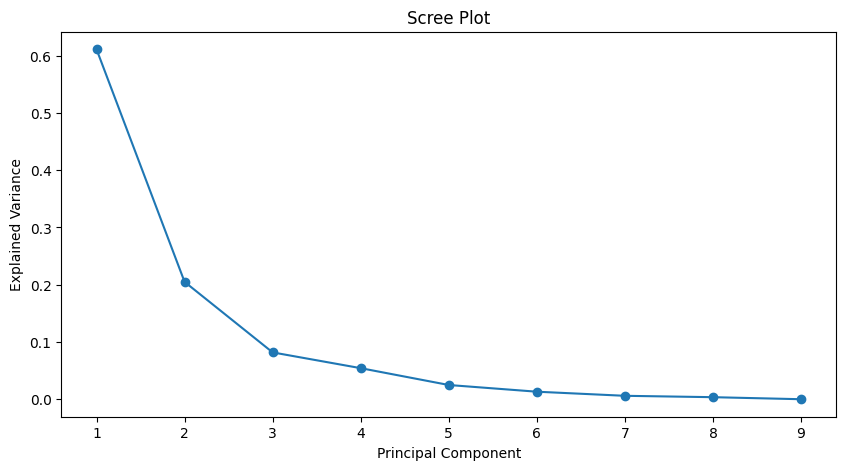

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(
range(1,len(variancia_explicada)+1),
variancia_explicada,
marker="o"
)
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance")
plt.show()
#

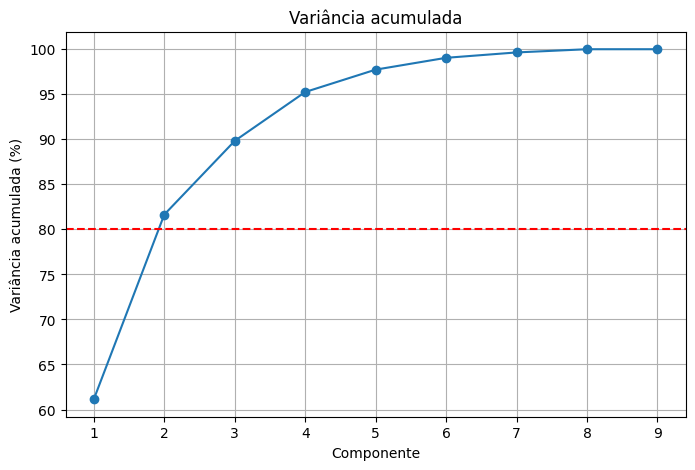

Componentes para 90% da variância: 4
Componentes para 95% da variância: 4
Componentes para 99% da variância: 6


In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(variancia_acumulada)+1), variancia_acumulada*100, marker='o')
plt.axhline(80, color='red', linestyle='--')
plt.xlabel("Componente")
plt.ylabel("Variância acumulada (%)")
plt.title("Variância acumulada")
plt.grid()
plt.show()

# ============================================
#  Mostrar quantos componentes são necessários
# ============================================
comp_90 = np.argmax(variancia_acumulada >= 0.90) + 1
comp_95 = np.argmax(variancia_acumulada >= 0.95) + 1
comp_99 = np.argmax(variancia_acumulada >= 0.99) + 1

print(f"Componentes para 90% da variância: {comp_90}")
print(f"Componentes para 95% da variância: {comp_95}")
print(f"Componentes para 99% da variância: {comp_99}")

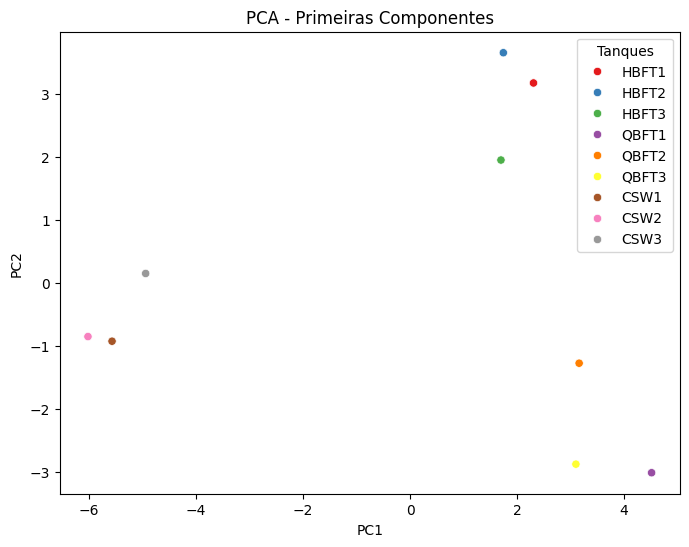

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, palette="Set1")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Primeiras Componentes")
plt.savefig('PCA.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
cargas = pd.DataFrame(pca.components_.T,
                      columns=[f"PC{i+1}" for i in range(pca.n_components_)],
                      index=X_corr.columns)
cargas

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
filament1_mean,0.233765,-0.142136,0.062559,0.099575,0.002030,-0.047154,-0.030961,0.065175,0.111799
sst_mean,0.234406,0.128616,-0.024844,0.014562,-0.225940,0.073128,0.058761,0.122977,-0.190973
turb_mean,0.226642,0.131437,-0.062216,0.155203,-0.266162,0.083362,0.041097,0.088895,-0.201998
coc2_mean,0.244140,-0.023967,0.110907,0.059391,-0.081560,-0.005960,-0.114085,0.359011,0.124338
ph_mean,-0.240512,0.078299,0.015993,-0.000457,-0.159660,0.206540,0.309308,-0.119306,-0.176240
fag2_mean,0.242776,0.063272,0.023399,0.047552,-0.079695,-0.282447,0.134555,-0.185668,0.117538
coc2_std,0.229958,-0.037548,0.149986,0.248206,-0.086000,-0.084337,-0.248326,-0.058801,-0.137010
o2m_mean,-0.178488,-0.269364,0.045978,-0.227659,0.051413,0.061648,-0.198529,0.465518,-0.081084
vibri1_mean,-0.234891,-0.137512,0.045158,-0.055908,0.133202,0.039415,0.028135,-0.116352,0.061123
nitra_mean,0.166211,-0.315770,0.047868,0.120847,0.063019,0.041230,0.068133,-0.010309,-0.324167


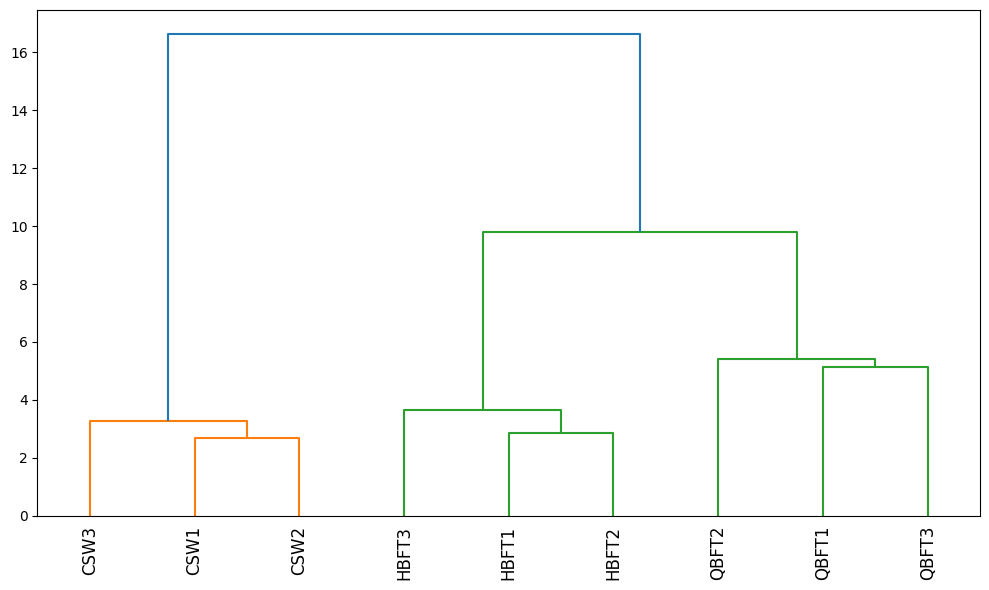

In [ ]:
Z = linkage(
X_scaled,
method="ward"
)
plt.figure(figsize=(10,6))
dendrogram(
Z,
labels=y_corr.values,
leaf_rotation=90
)
plt.tight_layout()

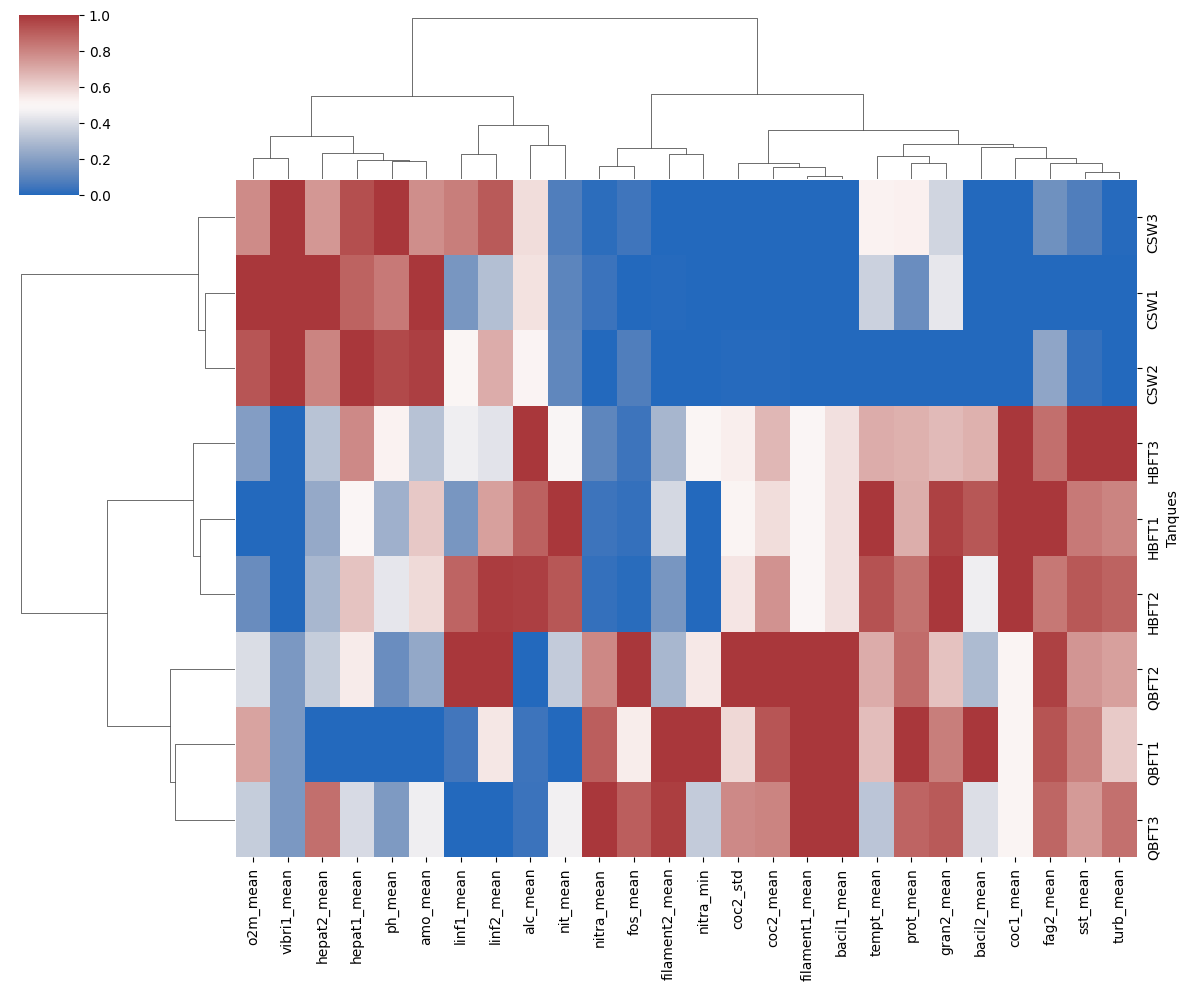

In [ ]:
# Criando o DataFrame escalado
dados_heat = pd.DataFrame(
    X_scaled,
    index=y_corr,
    columns=X_corr.columns
)

# Substituindo eventuais NaNs iniciais por 0
dados_heat = dados_heat.fillna(0)

# REMOVENDO colunas constantes (variância zero), que causam erro na normalização interna do clustermap
colunas_filtradas = dados_heat.columns[dados_heat.std() > 0]
dados_heat_filtrado = dados_heat[colunas_filtradas]

# Gerando o clustermap sem colunas que possam causar divisão por zero
sns.clustermap(
    dados_heat_filtrado,
    method="ward",
    cmap="vlag",
    figsize=(12,10),
    standard_scale=1
)

In [ ]:
corr = X_corr.corr(
method="spearman"
)
print(corr)

                filament1_mean  sst_mean  turb_mean  coc2_mean   ph_mean  \
filament1_mean        1.000000  0.474342   0.527046   0.948683 -0.948683   
sst_mean              0.474342  1.000000   0.883333   0.500000 -0.416667   
turb_mean             0.527046  0.883333   1.000000   0.516667 -0.366667   
coc2_mean             0.948683  0.500000   0.516667   1.000000 -0.883333   
ph_mean              -0.948683 -0.416667  -0.366667  -0.883333  1.000000   
fag2_mean             0.790569  0.566667   0.483333   0.733333 -0.816667   
coc2_std              0.948683  0.466667   0.566667   0.983333 -0.850000   
o2m_mean             -0.474342 -0.866667  -0.883333  -0.433333  0.416667   
vibri1_mean          -0.500000 -0.948683  -0.895979  -0.474342  0.474342   
nitra_mean            0.895979  0.316667   0.416667   0.733333 -0.850000   
amo_mean             -0.895979 -0.633333  -0.566667  -0.916667  0.816667   
prot_mean             0.948683  0.466667   0.483333   0.883333 -0.916667   
hepat1_mean 

(np.float64(-1.0939066343052473),
 np.float64(0.9720393204101963),
 np.float64(-0.9722130527858314),
 np.float64(0.9897989693410065))

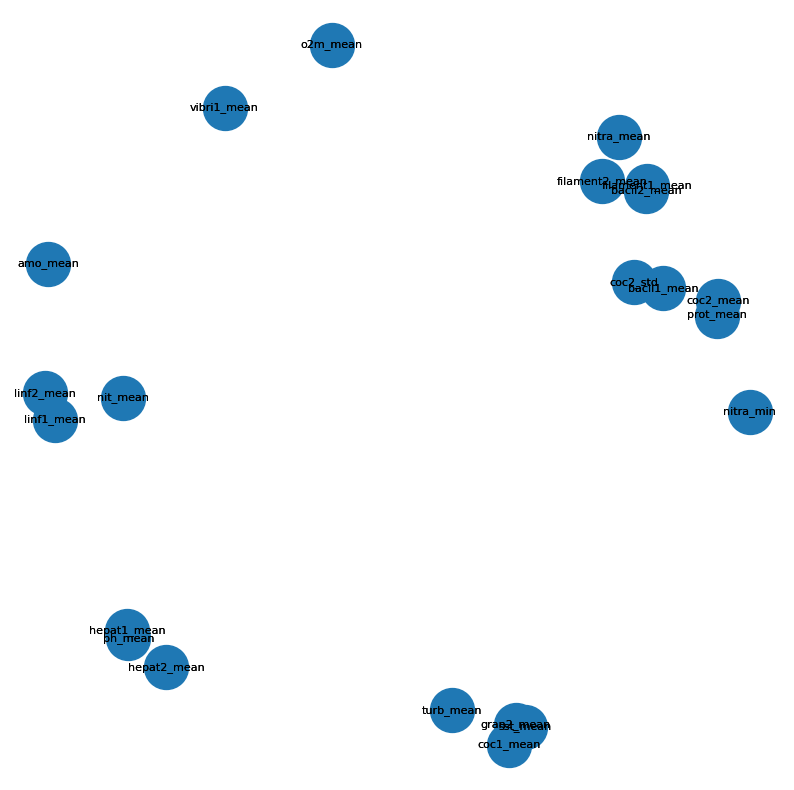

In [ ]:
G = nx.Graph()
limite = 0.85
for i in corr.columns:
  for j in corr.columns:
    if i == j:
      continue
    valor = corr.loc[i,j]
    if abs(valor) >= limite:
      G.add_edge(
          i,
          j,
          weight=valor)
plt.figure(figsize=(10,10))
pos = nx.spring_layout(G, seed = 42)
nx.draw_networkx_nodes(G, pos, node_size=1000)
nx.draw_networkx_labels(G,pos,font_size=8)
nx.draw_networkx_labels(G,pos,font_size=8)

plt.axis("off")